# 01: Exploratory Data Analysis & Macro Price Dynamics

### Notebook Purpose & Research Objectives
This notebook analyzes weekly price trajectories, structural inflation breaks (notably the 2022 Sri Lankan economic crisis), category-level price distributions, and unit differences across agricultural commodities.

---


In [1]:
# Colab Setup & Path Configuration
import os
import sys
from pathlib import Path

# Check if running in Google Colab
if 'google.colab' in sys.modules:
    from google.colab import drive
    drive.mount('/content/drive')
    proj_dir = Path('/content/drive/MyDrive/veg_price_forecasting')
    if proj_dir.exists():
        os.chdir(proj_dir)
        sys.path.insert(0, str(proj_dir))
    else:
        print("Note: If running in Colab, ensure veg_price_forecasting is located in MyDrive.")
else:
    proj_dir = Path.cwd().resolve()
    if proj_dir.name == "notebooks":
        proj_dir = proj_dir.parent
    os.chdir(proj_dir)
    sys.path.insert(0, str(proj_dir))

print(f"Active Working Directory: {Path.cwd()}")


Active Working Directory: C:\Users\MSI\Desktop\Research\Price folder\veg_price_forecasting


### 1. Macro Price Trends (2017 - 2026)

2026-10-01 15:25:46,133 [INFO] src.data: Raw data SHA-256 integrity check verified successfully.


2026-10-01 15:25:46,224 [INFO] src.data: Loaded 464 weeks and 14848 long records for 32 vegetables.


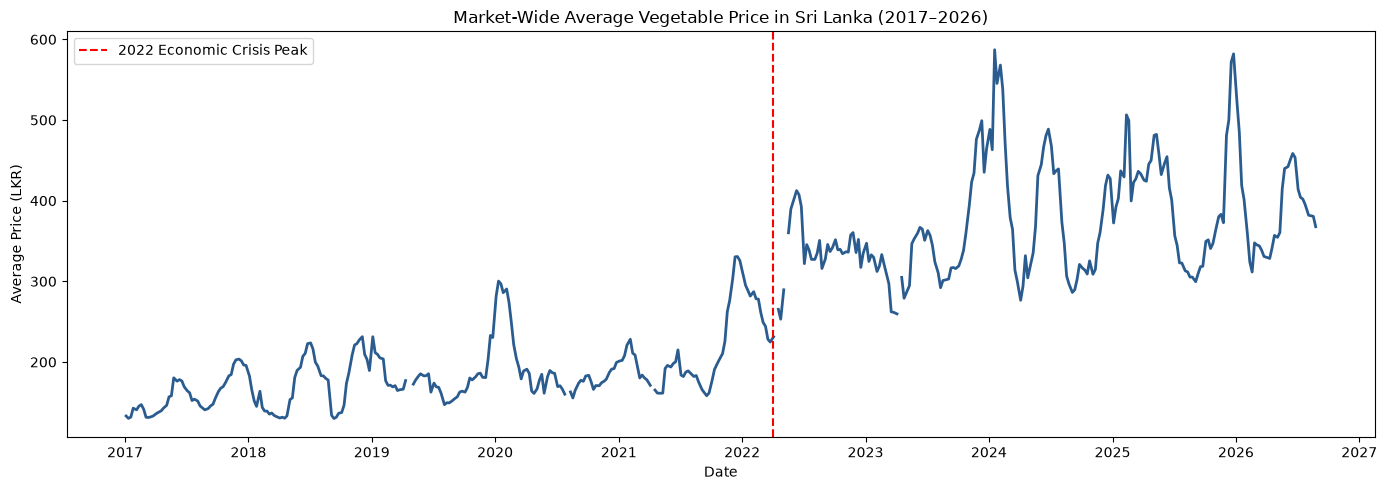

In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from src.data import load_and_preprocess_vegetables
from src.utils import load_config

cfg = load_config("config.yaml")
df_wide, df_long = load_and_preprocess_vegetables(cfg)

# Mean market price across all vegetables over time
market_trend = df_long.groupby("approx_date")["price_lkr"].mean().reset_index()
market_trend["approx_date"] = pd.to_datetime(market_trend["approx_date"])

plt.figure(figsize=(14, 5))
plt.plot(market_trend["approx_date"], market_trend["price_lkr"], color="#2b5c8f", lw=2)
plt.axvline(pd.to_datetime("2022-04-01"), color="red", linestyle="--", label="2022 Economic Crisis Peak")
plt.title("Market-Wide Average Vegetable Price in Sri Lanka (2017–2026)")
plt.xlabel("Date")
plt.ylabel("Average Price (LKR)")
plt.legend()
plt.tight_layout()
plt.show()


### 2. Agro-Climatic Category Price Distributions

C:\Users\MSI\AppData\Local\Temp\ipykernel_8520\1894666084.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_long, x="category", y="price_lkr", palette="Set2")


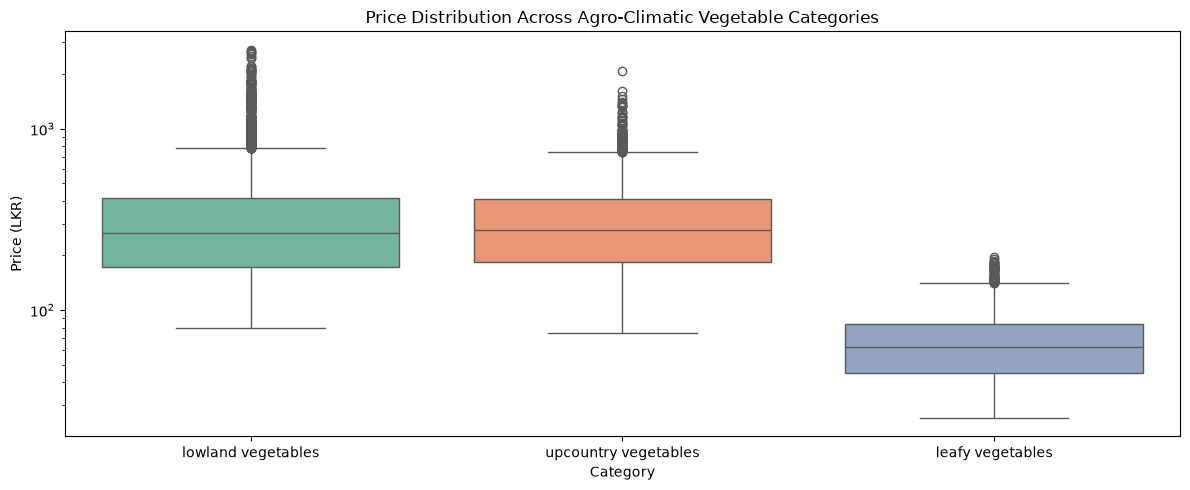

In [3]:
plt.figure(figsize=(12, 5))
sns.boxplot(data=df_long, x="category", y="price_lkr", palette="Set2")
plt.title("Price Distribution Across Agro-Climatic Vegetable Categories")
plt.xlabel("Category")
plt.ylabel("Price (LKR)")
plt.yscale("log")
plt.tight_layout()
plt.show()


### 3. Seasonality Patterns

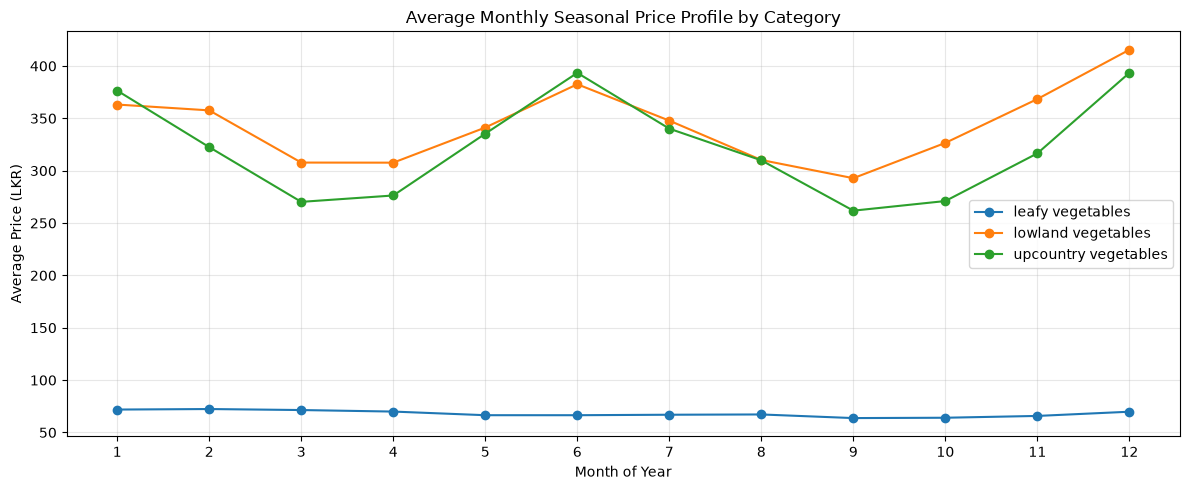

In [4]:
monthly_seasonality = df_long.groupby(["category", "month"])["price_lkr"].mean().unstack(level=0)
plt.figure(figsize=(12, 5))
for col in monthly_seasonality.columns:
    plt.plot(monthly_seasonality.index, monthly_seasonality[col], marker="o", label=col)
plt.title("Average Monthly Seasonal Price Profile by Category")
plt.xlabel("Month of Year")
plt.ylabel("Average Price (LKR)")
plt.xticks(range(1, 13))
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


---
### Research Findings & Plain Language Interpretation
Key EDA conclusions:
- The 2022 macroeconomic currency devaluation caused a massive structural upward shift across all vegetable series, making log-differencing and robust scaling essential.
- Upcountry vegetables (e.g. Carrot, Leeks, Beetroot) demonstrate substantially higher price levels and seasonal volatility than lowland produce.
- Units differ across commodities (kg vs bunch vs 500g); evaluating models via scale-free relative metrics (MASE, sMAPE) is imperative for fair model comparison.
